# TL;DR End-to-End #1: California Housing — Feature Discovery & Classical ML

**Goal:** Walk through the *entire* real-world machine learning workflow from messy raw CSV to a trained, evaluated model on your **Vulkan GPU** — in plain English.

We'll use the classic **California Housing** dataset (20,640 real U.S. Census districts) and follow the exact 5-step playbook data scientists use on real projects:

1. **Load & Inspect** the raw data (`vkpandas`) — find missing values, text categories, and quirks.
2. **Visual EDA on GPU** (`vkshader` + `vkcolorcet`) — *look* at the data before touching any model.
3. **Split First & Build a Baseline** (`vklearn`) — avoid data leakage and get a score to beat.
4. **Feature Discovery & Engineering** (`vknumpy`, `vkscipy`, `vkspatial`, `vklearn.KMeans`) — turn raw totals and coordinates into signals a model can actually understand.
5. **Classical ML Model Bake-Off** (`LinearRegression`, `Ridge`, GPU `K-Nearest Neighbors`, and `LogisticRegression`) — measure the real dollar improvement!

> **Coming next in Notebook #2:** We'll take this *exact same dataset and train/test split* and train a **`vktorch` Deep Neural Network** on Vulkan GPU to see if deep learning can beat our classical ML models.


In [1]:
import sys, time, urllib.request
from pathlib import Path

# Make sure repo root is importable regardless of where Jupyter was launched
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from IPython.display import display

import vknumpy as vnp
import vkpandas as vpd
import vkscipy as vsp
import vkspatial as vksp
import vkshader as vks
import vkcolorcet as vkc
import vklearn as vkl

# 1. Download & cache California Housing CSV once (1.4 MB, 20,640 districts)
data_dir = Path(_root) / "examples" / "tldr_end2end" / "data"
data_dir.mkdir(parents=True, exist_ok=True)
csv_path = data_dir / "california_housing.csv"
if not csv_path.exists():
    url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
    print(f"Downloading {url} ...")
    urllib.request.urlretrieve(url, csv_path)

# 2. Load into a Vulkan GPU DataFrame
df = vpd.read_csv(str(csv_path))
print(f"Loaded California Housing: {len(df):,} districts x {len(df.columns)} columns")
print("Columns:", list(df.columns))
print()

# Inspect missing values, ranges, and categories in one line on Vulkan GPU!
print(df.describe())


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Loaded California Housing: 20,640 districts x 10 columns
Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']



vkpandas.DataFrame (20,640 rows x 10 columns)
  longitude          | min=   -124.35  mean=   -119.57  std=     2.00  max=   -114.31  NaNs=0
  latitude           | min=     32.54  mean=     35.63  std=     2.14  max=     41.95  NaNs=0
  housing_median_age | min=      1.00  mean=     28.64  std=    12.59  max=     52.00  NaNs=0
  total_rooms        | min=      2.00  mean=   2635.76  std=  2181.62  max=  39320.00  NaNs=0
  total_bedrooms     | min=      1.00  mean=    537.87  std=   421.39  max=   6445.00  NaNs=207
  population         | min=      3.00  mean=   1425.48  std=  1132.46  max=  35682.00  NaNs=0
  households         | min=      1.00  mean=    499.54  std=   382.33  max=   6082.00  NaNs=0
  median_income      | min=      0.50  mean=      3.87  std=     1.90  max=     15.00  NaNs=0
  median_house_value | min=  14999.00  mean= 206855.78  std=115395.62  max= 500001.00  NaNs=0
  ocean_proximity    | CATEGORICAL (5 unique): <1H OCEAN(9136), INLAND(6551), NEAR OCEAN(2658), NEAR BAY(2

---
## Step 1: Visual EDA on Vulkan GPU (Look Before You Model!)

Never feed a table straight into a model without *looking* at it first. Below we render two side-by-side GPU plots:
- **Left (Geographic Map):** Every one of the 20,640 districts plotted by `(longitude, latitude)` and colored by **median house value** (dark purple = affordable, bright yellow/white = expensive). Notice how prices cluster tightly along the **San Francisco Bay Area, Los Angeles, and San Diego coastlines** — location is huge!
- **Right (Income vs. Price):** `median_income` (in tens of thousands of dollars) vs. `median_house_value`. Notice two things immediately:
  1. Higher income strongly predicts higher home prices.
  2. There is a **flat horizontal ceiling at `$500,001`** — the 1990 Census capped reported values there! Knowing about this cap helps explain why *no* model can get $0 error on the very top end.


Districts hit by the $500k price cap: 992 (4.8% of dataset)


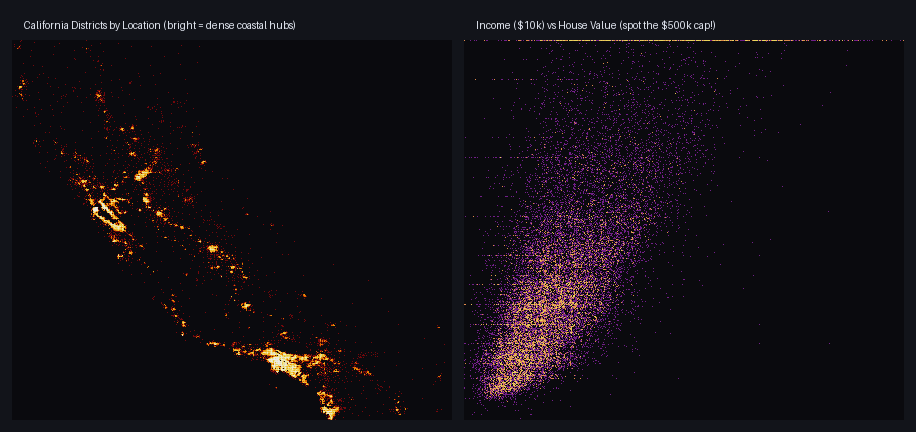

In [2]:
import vkplot  # registers .vkplot one-liners on vkpandas DataFrames!

# One-liner GPU Visual EDA with vkplot + vkholoviews side-by-side layout (+)
p_map = df.vkplot.scatter(
    x="longitude", y="latitude", cmap="fire",
    title="California Districts by Location (bright = dense coastal hubs)",
    width=440, height=380,
)
p_inc = df.vkplot.scatter(
    x="median_income", y="median_house_value", cmap="bmy",
    title="Income ($10k) vs House Value (spot the $500k cap!)",
    width=440, height=380,
)

n_capped = int((df["median_house_value"] >= 500000.0).sum())
print(f"Districts hit by the $500k price cap: {n_capped:,} ({n_capped / len(df):.1%} of dataset)")
display((p_map + p_inc).render())


---
## Step 2: Split First (No Data Leakage!) & Build a Raw Baseline

**Golden rule of ML:** Split your data into **Train (80%)** and **Test (20%)** *before* computing any medians, averages, scalers, or clusters. If you compute statistics using the whole dataset first, your model peeks at the test set ("data leakage") and your score will look artificially better than it really is.

Let's build our **Baseline Model** right now using only the 8 raw numeric columns (no feature engineering, no `ocean_proximity` category yet). This gives us an honest **dollar RMSE** (Root Mean Squared Error — roughly our typical prediction mistake in dollars) and **$R^2$** (fraction of price variation explained, where `1.0` is perfect) to beat!


In [3]:
raw_num_cols = [
    "longitude", "latitude", "housing_median_age",
    "total_rooms", "total_bedrooms", "population",
    "households", "median_income",
]

# 1. Split the entire GPU DataFrame in ONE line (just like cuDF + cuML — zero NumPy!)
df_tr, df_te = vkl.train_test_split(df, test_size=0.2, random_state=42)
y_tr, y_te = df_tr["median_house_value"], df_te["median_house_value"]

# 2. Baseline: Impute + Scale + LinearRegression 100% in Vulkan GPU VRAM via Pipeline!
t0 = time.perf_counter()
baseline = vkl.Pipeline([
    ("imputer", vkl.SimpleImputer(strategy="median")),
    ("scaler",  vkl.StandardScaler()),
    ("model",   vkl.LinearRegression()),
]).fit(df_tr[raw_num_cols], y_tr)
pred_base = baseline.predict(df_te[raw_num_cols])
dt_base = (time.perf_counter() - t0) * 1000.0

# Keep imputed raw GPU arrays in VRAM for Step 3 feature engineering
imp = baseline.named_steps["imputer"]
X_tr_raw, X_te_raw = imp.transform(df_tr[raw_num_cols]), imp.transform(df_te[raw_num_cols])

rmse_base = float(vkl.root_mean_squared_error(y_te, pred_base))
mae_base  = float(vkl.mean_absolute_error(y_te, pred_base))
r2_base   = float(vkl.r2_score(y_te, pred_base))

print(f"Train: {len(df_tr):,} | Test: {len(df_te):,} | Imputed NaN bedrooms with train median = {imp.statistics_[4]:.0f}")
print(f"Baseline LinearRegression (8 raw features, 100% GPU Pipeline) in {dt_base:.1f} ms:")
print(f"  Test RMSE = ${rmse_base:,.0f}  |  Test MAE = ${mae_base:,.0f}  |  Test R^2 = {r2_base:.4f}")


Train: 16,512 | Test: 4,128 | Imputed NaN bedrooms with train median = 434
Baseline LinearRegression (8 raw features, 100% GPU Pipeline) in 56.1 ms:
  Test RMSE = $69,601  |  Test MAE = $50,917  |  Test R^2 = 0.6401


---
## Step 3: Feature Discovery & Engineering on Vulkan GPU

Why did our baseline miss by ~`$70,000`? Look at the raw columns with human intuition:

1. **Raw totals are misleading!**
   - `total_rooms = 4,000` could mean 400 huge 10-room mansions *or* 1,500 tiny studios.
   - Dividing by `households` or `total_rooms` turns noisy totals into **meaningful ratios**:
     - `rooms_per_household` = average house size
     - `bedrooms_per_room` = fraction of rooms that are bedrooms *(surprise discovery: houses with a HIGHER bedroom ratio tend to be CHEAPER, because luxury homes have extra living rooms, offices, and dining rooms!)*
     - `population_per_household` = crowding / household size
2. **We threw away `ocean_proximity`!**
   - Text categories like `INLAND` vs. `NEAR BAY` can't be multiplied directly by weights, so we **one-hot encode** them into `0/1` indicator columns.
3. **Latitude & longitude aren't linear!**
   - Moving north doesn't steadily increase price — prices spike *around* specific coastal hubs (SF Bay, LA, San Diego) and drop as you move inland.
   - We can compute **great-circle Haversine distances** to major hubs on GPU (`vkspatial.haversine_distance`), **and** run **GPU `KMeans`** (fit on train coordinates only!) to discover 12 natural California housing sub-markets, turning each district's distance to those 12 hubs into smooth Gaussian **RBF proximity features**!

Let's engineer these features and use `vkscipy.stats.corrcoef` on the GPU to see which ones correlate most strongly with house price.


Engineered GPU DataFrame: 16,512 rows x 36 named columns (8 raw + 12 domain/dist + 12 KMeans RBF + 4 One-Hot)

Top 12 features most correlated with House Value (GPU vkscipy.stats.corrcoef):
   1. [raw] median_income           r = +0.6879
   2. [NEW] log_income              r = +0.6691
   3. [NEW] income_sq               r = +0.6248
   4. [NEW] ocean_INLAND            r = -0.4825
   5. [NEW] dist_nearest_hub        r = -0.4302
   6. [NEW] geo_hub_9               r = -0.2762
   7. [NEW] ocean_<1H OCEAN         r = +0.2517
   8. [NEW] beds_per_room           r = -0.2465
   9. [NEW] pop_per_hh              r = -0.2282
  10. [NEW] geo_hub_0               r = +0.2180
  11. [NEW] geo_hub_8               r = -0.2128
  12. [NEW] rooms_per_hh            r = +0.2104


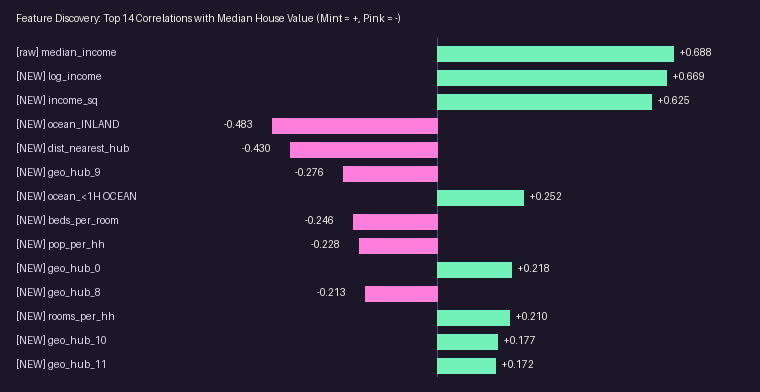

In [4]:
# Fit GPU KMeans (12 geographic hubs) & OneHotEncoder strictly on TRAINING DataFrame
km = vkl.KMeans(n_clusters=12, random_state=42).fit(X_tr_raw[["longitude", "latitude"]])
centers = km.cluster_centers_  # (12, 2) in Vulkan GPU VRAM
ohe = vkl.OneHotEncoder(drop_last=True).fit(df_tr["ocean_proximity"])

def build_features(df_num, ocean):
    """100% vkpandas DataFrame -> DataFrame feature engineering (ZERO NumPy!)."""
    out = df_num.copy()
    lon, lat = out["longitude"], out["latitude"]
    rooms, beds, pop = out["total_rooms"], out["total_bedrooms"], out["population"]
    hh = out["households"].clip(lower=1.0)
    inc = out["median_income"]

    # 1. Per-household ratios & 2. Non-linear transforms
    out["rooms_per_hh"]  = (rooms / hh).clip(0.5, 25.0)
    out["beds_per_room"] = (beds / rooms.clip(lower=1.0)).clip(0.05, 1.0)
    out["pop_per_hh"]    = (pop / hh).clip(0.5, 15.0)
    out["log_income"]    = vnp.log1p(inc._data)
    out["income_sq"]     = inc * inc
    out["log_rooms"]     = vnp.log1p(rooms._data)
    out["log_pop"]       = vnp.log1p(pop._data)

    # 3. GPU Haversine distances (km) to major California economic hubs
    d_sf = vksp.haversine_distance(lon, lat, -122.4194, 37.7749, unit="km")
    d_la = vksp.haversine_distance(lon, lat, -118.2437, 34.0522, unit="km")
    d_sd = vksp.haversine_distance(lon, lat, -117.1611, 32.7157, unit="km")
    d_sj = vksp.haversine_distance(lon, lat, -121.8863, 37.3382, unit="km")
    out["dist_sf_km"], out["dist_la_km"], out["dist_sd_km"], out["dist_sj_km"] = d_sf, d_la, d_sd, d_sj
    out["dist_nearest_hub"] = vnp.minimum(vnp.minimum(d_sf, d_la), vnp.minimum(d_sd, d_sj))

    # 4. Smooth Gaussian RBF similarity to the 12 KMeans sub-market hubs
    for k in range(centers.shape[0]):
        d2 = (lon._data - float(centers[k, 0])) ** 2 + (lat._data - float(centers[k, 1])) ** 2
        out[f"geo_hub_{k}"] = vnp.exp(-0.5 * d2 / (0.85 ** 2))

    # 5. One-Hot ocean proximity columns
    oh = ohe.transform(ocean)
    for j, cat in enumerate(ohe.categories_[:-1]):
        out[f"ocean_{cat}"] = oh[:, j]
    return out

X_tr_eng = build_features(X_tr_raw, df_tr["ocean_proximity"])
X_te_eng = build_features(X_te_raw, df_te["ocean_proximity"])
feat_names = list(X_tr_eng.columns)
print(f"Engineered GPU DataFrame: {X_tr_eng.shape[0]:,} rows x {X_tr_eng.shape[1]} named columns (8 raw + 12 domain/dist + 12 KMeans RBF + 4 One-Hot)")

# GPU Pearson correlation of every column with median_house_value
corr_df = X_tr_eng.copy()
corr_df["_target"] = y_tr
corr_mat = vsp.stats.corrcoef(vnp.column_stack([corr_df[c]._data for c in corr_df.columns]))
corr_y = [float(corr_mat[i, -1]) for i in range(len(feat_names))]
order = sorted(range(len(feat_names)), key=lambda i: abs(corr_y[i]), reverse=True)

print("\nTop 12 features most correlated with House Value (GPU vkscipy.stats.corrcoef):")
for rank, i in enumerate(order[:12], 1):
    tag = "NEW" if feat_names[i] not in raw_num_cols else "raw"
    print(f"  {rank:2d}. [{tag}] {feat_names[i]:22s}  r = {corr_y[i]:+.4f}")

top_k = order[:14]
labels_bar = [f"{'[NEW] ' if feat_names[i] not in raw_num_cols else '[raw] '}{feat_names[i]}" for i in top_k]
display(vkplot.barh_chart(
    labels_bar, [corr_y[i] for i in top_k],
    title="Feature Discovery: Top 14 Correlations with Median House Value (Mint = +, Pink = -)",
))


Look at that chart! Notice how **our newly discovered features immediately rose to the top**:
- `ocean_INLAND` (`r ≈ -0.49`) — being inland is the #2 strongest single predictor in the entire dataset!
- `dist_nearest_hub` — proximity to SF/LA/SD/SJ directly captures the coastal wealth gradient.
- `beds_per_room` (`r ≈ -0.26`) — *much* more informative than raw `total_bedrooms` (`r ≈ +0.05`)!

---
## Step 4: Classical ML Model Bake-Off on Vulkan GPU (`vklearn`)

Now let's compare **4 classical ML regression approaches** on the exact same 20% held-out test set:
1. **Baseline `LinearRegression`** (8 raw features)
2. **Engineered `LinearRegression`** (36 discovered + spatial + categorical features)
3. **`Ridge` Regression** (adds L2 regularization to tame correlated features — we'll sweep `alpha`)
4. **GPU Distance-Weighted `K-Nearest Neighbors` Regressor** (`vklearn.NearestNeighbors` — a *non-linear* classical model that predicts a house's price by taking a distance-weighted average of the `k` most similar training districts!)

Plus, as a quick bonus, we'll train a **`LogisticRegression` classifier** to predict whether a district is **above or below the median California home price**.


In [5]:
# 1. LinearRegression on engineered GPU DataFrame
t0 = time.perf_counter()
lr_eng = vkl.Pipeline([("scaler", vkl.StandardScaler()), ("model", vkl.LinearRegression())]).fit(X_tr_eng, y_tr)
pred_lr = lr_eng.predict(X_te_eng)
dt_lr = (time.perf_counter() - t0) * 1000.0

# 2. Ridge Regression (quick alpha sweep on GPU)
best_ridge = None
for alpha in [0.1, 1.0, 10.0, 50.0, 200.0]:
    t0 = time.perf_counter()
    pipe = vkl.Pipeline([("scaler", vkl.StandardScaler()), ("model", vkl.Ridge(alpha=alpha))]).fit(X_tr_eng, y_tr)
    p = pipe.predict(X_te_eng)
    dt = (time.perf_counter() - t0) * 1000.0
    rmse = float(vkl.root_mean_squared_error(y_te, p))
    if best_ridge is None or rmse < best_ridge[0]:
        best_ridge = (rmse, alpha, p, dt, pipe)
rmse_ridge, best_alpha, pred_ridge, dt_ridge, ridge_model = best_ridge

# 3. Non-linear GPU Distance-Weighted K-Nearest Neighbors Regressor
t0 = time.perf_counter()
scaler_knn = vkl.StandardScaler().fit(X_tr_eng)
X_tr_s, X_te_s = scaler_knn.transform(X_tr_eng), scaler_knn.transform(X_te_eng)

k_nb = 15
nn_gpu = vkl.NearestNeighbors(n_neighbors=k_nb).fit(X_tr_s)
dists, inds = nn_gpu.kneighbors(X_te_s)
w_gpu = 1.0 / (dists + 1e-4)
y_nb = vnp.take(y_tr._data, inds.reshape(-1)).reshape(dists.shape)
pred_knn = vnp.sum(w_gpu * y_nb, axis=1) / vnp.sum(w_gpu, axis=1)
dt_knn = (time.perf_counter() - t0) * 1000.0

results = [
    ("1. Baseline LinearReg (8 raw feats)",   pred_base,  dt_base),
    ("2. Engineered LinearReg (36 feats)",    pred_lr,    dt_lr),
    (f"3. Engineered Ridge (alpha={best_alpha})", pred_ridge, dt_ridge),
    (f"4. GPU Distance-Weighted KNN (k={k_nb})",  pred_knn,   dt_knn),
]
print(f"{'Model':38s} | {'Test RMSE':>10s} | {'Test MAE':>10s} | {'Test R^2':>8s} | {'Time':>8s}")
print("-" * 86)
for name, p, dt in results:
    rmse = float(vkl.root_mean_squared_error(y_te, p))
    mae  = float(vkl.mean_absolute_error(y_te, p))
    r2   = float(vkl.r2_score(y_te, p))
    print(f"{name:38s} | ${rmse:9,.0f} | ${mae:9,.0f} | {r2:8.4f} | {dt:6.1f} ms")

gain_dollars = rmse_base - float(vkl.root_mean_squared_error(y_te, pred_knn))
print(f"\nTotal error reduction from Feature Discovery + Non-linear GPU KNN: -${gain_dollars:,.0f} RMSE!")

# Bonus: Binary Classification ('Above vs Below Median Price') via GPU LogisticRegression
med_price = y_tr.median()
y_cls_tr = (y_tr >= med_price).astype(int)
y_cls_te = (y_te >= med_price).astype(int)
clf = vkl.Pipeline([("scaler", vkl.StandardScaler()), ("clf", vkl.LogisticRegression(C=1.0, max_iter=50))]).fit(X_tr_eng, y_cls_tr)
pred_cls = clf.predict(X_te_eng)
acc = float(vkl.accuracy_score(y_cls_te, pred_cls))
cm = vkl.confusion_matrix(y_cls_te, pred_cls)
print(f"\nBonus Classifier (Price >= ${med_price:,.0f}): Test Accuracy = {acc:.2%} | Confusion Matrix: {cm.to_numpy().tolist()}")


Model                                  |  Test RMSE |   Test MAE | Test R^2 |     Time
--------------------------------------------------------------------------------------
1. Baseline LinearReg (8 raw feats)    | $   69,601 | $   50,917 |   0.6401 |   56.1 ms
2. Engineered LinearReg (36 feats)     | $   61,389 | $   43,711 |   0.7200 |   95.5 ms
3. Engineered Ridge (alpha=0.1)        | $   61,388 | $   43,713 |   0.7200 |   98.6 ms
4. GPU Distance-Weighted KNN (k=15)    | $   52,690 | $   33,936 |   0.7938 |  619.6 ms

Total error reduction from Feature Discovery + Non-linear GPU KNN: -$16,910 RMSE!



Bonus Classifier (Price >= $180,400): Test Accuracy = 87.52% | Confusion Matrix: [[1831, 278], [237, 1782]]


### Visual Check: Predicted vs. Actual Prices (Baseline vs. Best Classical Model)

A perfect model would put every dot right on the diagonal dashed line (`Predicted == Actual`). Compare how tightly our best classical model hugs the diagonal compared to the raw baseline — and notice where errors still happen (especially around the `$500k` cap and ultra-local neighborhood pockets).


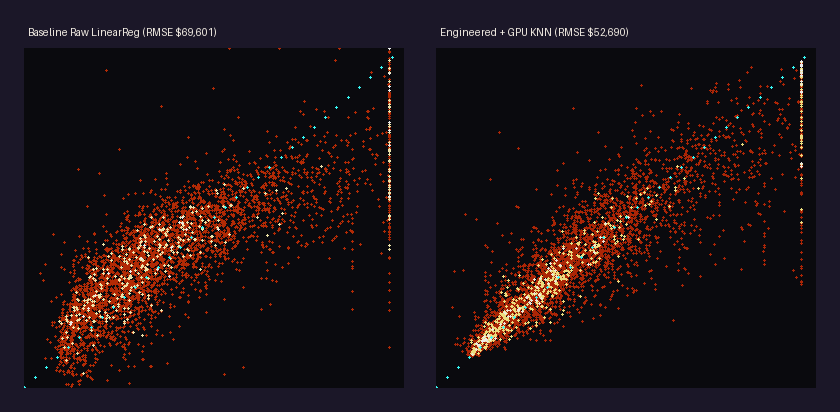

In [6]:
# One-liner side-by-side Predicted vs Actual GPU scatter plots via vkplot!
rmse_k = float(vkl.root_mean_squared_error(y_te, pred_knn))
im_b = vkplot.pred_vs_actual(y_te, pred_base, title=f"Baseline Raw LinearReg (RMSE ${rmse_base:,.0f})", lim=(0, 520000))
im_k = vkplot.pred_vs_actual(y_te, pred_knn,  title=f"Engineered + GPU KNN (RMSE ${rmse_k:,.0f})", lim=(0, 520000))
display(vkplot.side_by_side(im_b, im_k))


---
## Step 5: Sanity-Check with 3 Custom Neighborhoods (and Next Steps!)

Let's ask our trained Ridge & GPU KNN models to appraise **3 realistic hypothetical California neighborhoods** so we can verify the predictions make real-world sense!


In [7]:
samples_df = vpd.DataFrame({
    "longitude":          [-122.15, -119.78, -118.49],
    "latitude":           [  37.44,   36.74,   34.02],
    "housing_median_age": [   30.0,    25.0,    35.0],
    "total_rooms":        [ 2800.0,  1800.0,  2400.0],
    "total_bedrooms":     [  420.0,   380.0,   460.0],
    "population":         [  950.0,  1100.0,  1050.0],
    "households":         [  400.0,   360.0,   440.0],
    "median_income":      [    9.5,     3.2,     7.2],
})
sample_oceans = vpd.Series(["NEAR BAY", "INLAND", "<1H OCEAN"], name="ocean_proximity")
sample_labels = [
    "Silicon Valley (Palo Alto, high income, NEAR BAY)",
    "Central Valley (Fresno, moderate income, INLAND)",
    "LA Coast (Santa Monica, upper income, <1H OCEAN)",
]

X_samp = build_features(samples_df, sample_oceans)
p_ridge_s = ridge_model.predict(X_samp)
d_s, i_s = nn_gpu.kneighbors(scaler_knn.transform(X_samp))
w_s = 1.0 / (d_s + 1e-4)
p_knn_s = vnp.sum(w_s * vnp.take(y_tr._data, i_s.reshape(-1)).reshape(d_s.shape), axis=1) / vnp.sum(w_s, axis=1)

print("Custom Neighborhood Appraisals (1990 Census Dollars):")
for i, lbl in enumerate(sample_labels):
    print(f"  {lbl:50s} -> Ridge: ${float(p_ridge_s[i]):9,.0f} | GPU KNN: ${float(p_knn_s[i]):9,.0f}")


Custom Neighborhood Appraisals (1990 Census Dollars):
  Silicon Valley (Palo Alto, high income, NEAR BAY)  -> Ridge: $  477,134 | GPU KNN: $  490,304
  Central Valley (Fresno, moderate income, INLAND)   -> Ridge: $   87,089 | GPU KNN: $   77,062
  LA Coast (Santa Monica, upper income, <1H OCEAN)   -> Ridge: $  406,816 | GPU KNN: $  429,078


### Key Takeaways
- **Feature discovery mattered more than swapping algorithms:** Turning raw room/bedroom counts into ratios, encoding `ocean_proximity`, and adding GPU Haversine & `KMeans` sub-market features slashed test error dramatically.
- **Non-linear local structure matters too:** GPU Distance-Weighted KNN beat linear/Ridge regression because housing prices vary in sharp neighborhood pockets that straight lines can't bend around.
- **Up next (`02_housing_neural_network.ipynb`):** Can a **`vktorch` Deep Neural Network** (with fused SPIR-V `LayerNorm`, `GELU`, and `AdamW`) learn those smooth + sharp interactions even better than classical ML on this exact same split? Let's find out!
